# Simple logistic classifier with both the color of the pixel and the position of the pixel

Another simple classifier with the addition of new features to get where these pixels are situated

In [1]:
import matplotlib.pyplot as plt

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, binary_target_mask, make_data_splits, build_pixel_dataset, image_features,evaluate

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay


N_PIXELS = 100
WITH_POSITIONS = True

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

X_train, y_train = build_pixel_dataset(nyu, train_indices, target_ids, N_PIXELS, RANDOM_STATE,WITH_POSITIONS)
X_test, y_test = build_pixel_dataset(nyu, test_indices, target_ids, N_PIXELS, RANDOM_STATE,WITH_POSITIONS)

Train images: 1028
Validation images: 206
Test images: 215


AUC:      0.886
AP:       0.458
Accuracy: 0.772  (baseline 'always not floor': 0.885)
IoU:      0.302
              precision    recall  f1-score   support

   not floor       0.98      0.76      0.86     19035
       floor       0.32      0.86      0.46      2465

    accuracy                           0.77     21500
   macro avg       0.65      0.81      0.66     21500
weighted avg       0.90      0.77      0.81     21500



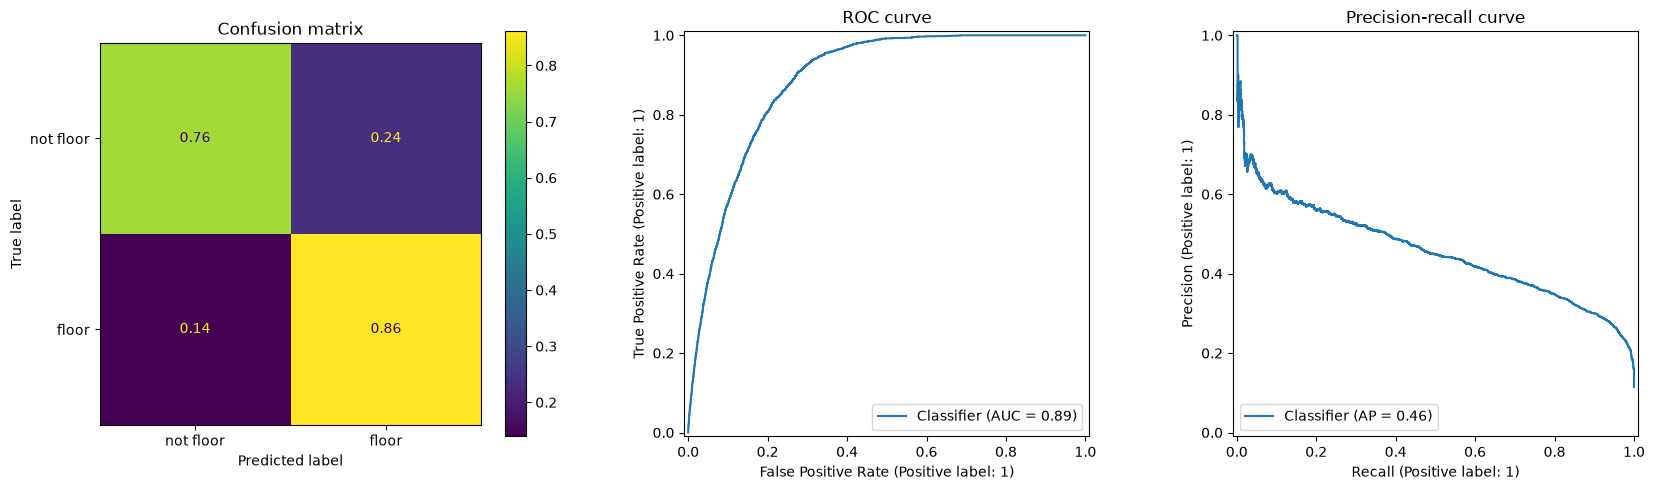

In [4]:
clf = LogisticRegression(class_weight="balanced", max_iter=1000)
clf.fit(X_train, y_train)

y_proba = clf.predict_proba(X_test)[:, 1]
evaluate(y_test, y_proba)

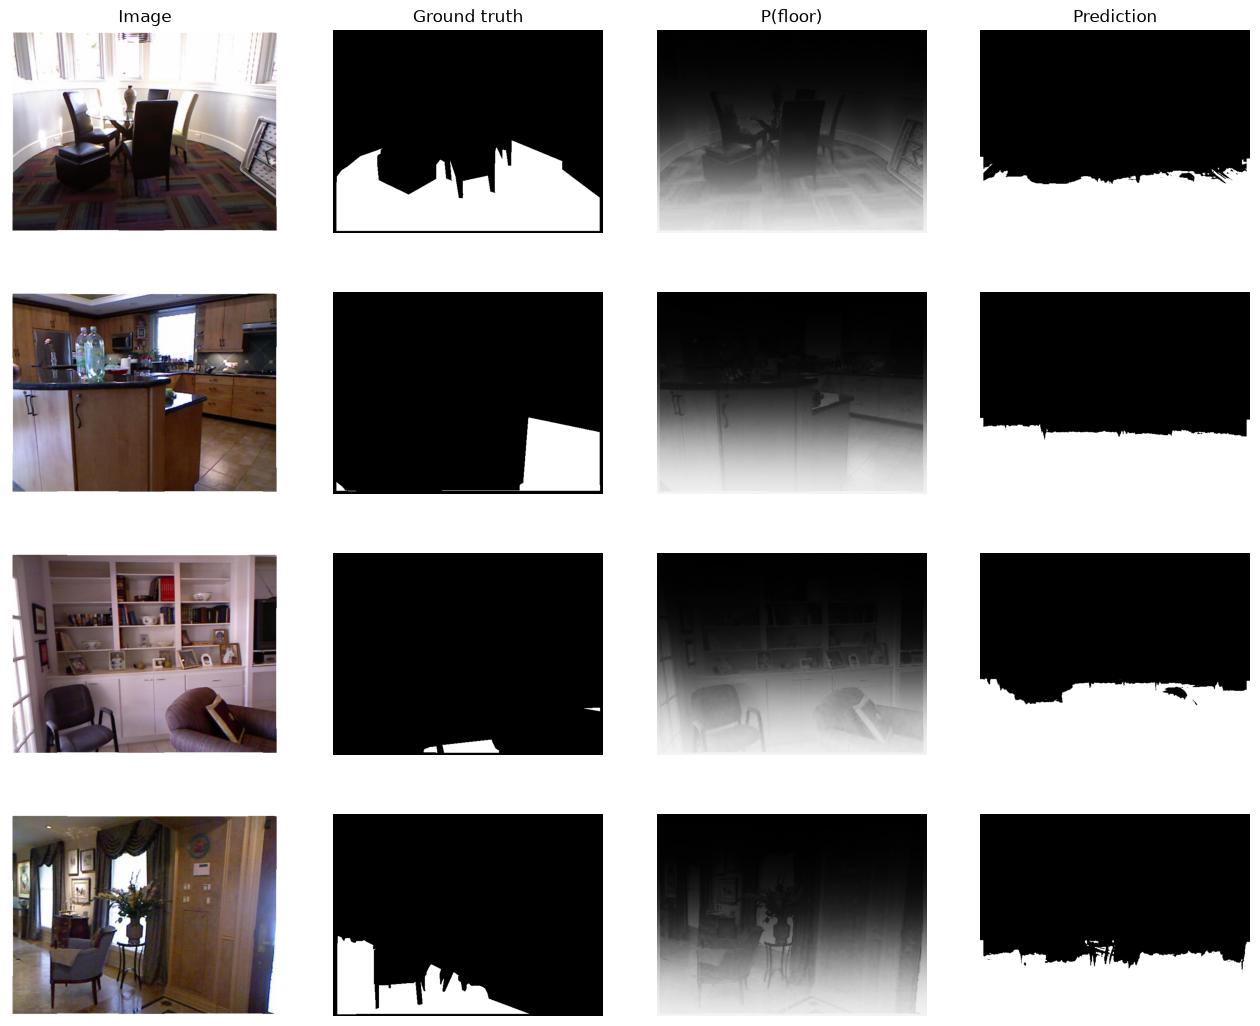

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)

    # Ground truth: 1 = floor, 0 = everything else
    gt = binary_target_mask(labels, target_ids)

    # Predict P(floor) for every pixel, then reshape back to image size
    X = image_features(image, with_position=True)
    proba = clf.predict_proba(X)[:, 1].reshape(labels.shape)

    # Final prediction
    pred = clf.predict(X).reshape(labels.shape)

    axes[row, 0].imshow(image)
    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()